[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/carlospi2000/Notes_on_Computational_Physics/blob/main/11.Fast_Fourier_Transform/FFT_ESTUDIANTES.ipynb)

# Semana 11a — Transformada rápida de Fourier (FFT)

**Física Computacional — 106018C** · Lenguaje: **Fortran y Python** · Capítulo 5: Matrices

Esta semana tiene dos notebooks:

| Notebook | Contenido |
|---|---|
| **11a** (este) | Por qué la DFT matricial es lenta · el algoritmo de Cooley-Tukey · la FFT recursiva en Python y en Fortran · costo $O(N\log_2 N)$ · aplicación: una señal oculta en el ruido · ejercicio de calentamiento 1 |
| **11b** | Introducción a la solución numérica de ecuaciones diferenciales: Euler, Runge-Kutta de orden 2 y de orden 4 · ejercicios de calentamiento 2 y 3 · **Taller 11** |

La FFT no tiene taller propio. Los **ejercicios de calentamiento**, en recuadros dorados, se trabajan en la clase del lunes y no se califican.

**Objetivos de este notebook**

1. Reconocer por qué la DFT matricial de la Semana 10 tiene costo $O(N^2)$ y qué estructura de la matriz $W$ permite evitarlo.
2. Deducir la división de la DFT en muestras pares e impares (algoritmo de Cooley-Tukey) y la operación mariposa.
3. Programar la FFT recursiva en Python y en Fortran, y verificarla contra la DFT matricial.
4. Medir el costo $O(N\log_2 N)$ y compararlo con $O(N^2)$.
5. Usar la FFT para encontrar una señal periódica oculta en el ruido.

In [2]:
# Preparación: bibliotecas de Python, colores del curso y herramientas de compilación
import time
import numpy as np
import matplotlib.pyplot as plt

AZUL, DORADO, ROJO, VERDE, GRIS, MORADO = "#162A54", "#C9972C", "#B02A20", "#2E7D32", "#7F7F7F", "#6A3D9A"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)

# F2PY compila con meson y ninja desde Python 3.12 (igual que en las Semanas 9 y 10)
!pip -q install meson ninja
!gfortran --version | head -n 1
print("NumPy", np.__version__)

GNU Fortran (Homebrew GCC 15.2.0_1) 15.2.0
NumPy 2.0.2


In [3]:
def matriz_dft(N):
    """Matriz de Fourier W de N x N, con W[j, k] = exp(-2 pi i j k / N) (Semana 10)."""
    k = np.arange(N)
    return np.exp(-2j*np.pi*np.outer(k, k)/N)

## 1. Punto de partida: la DFT matricial cuesta $O(N^2)$

En la Semana 10 la transformada discreta de Fourier de $N$ muestras se escribió como un producto matriz-vector,

$$X_j = \sum_{k=0}^{N-1} x_k\, \omega_N^{jk}, \qquad \omega_N = e^{-2\pi i/N}, \qquad \mathbf{X} = W\,\mathbf{x},$$

donde

- $x_k$ es la muestra $k$ de la señal;
- $X_j$ es el coeficiente de Fourier $j$, asociado a la frecuencia $f_j = j/T$;
- $\omega_N$ es la **raíz $N$-ésima de la unidad**: un número complejo de módulo 1 que cumple $\omega_N^N = 1$;
- $W$ es la matriz de Fourier, con elementos $W_{jk} = \omega_N^{jk}$.

El producto requiere $N^2$ multiplicaciones complejas. Con $N = 44\,100$ (un segundo de audio) son casi $2\times10^9$ multiplicaciones y una matriz de 29 GiB.

### 1.1 La matriz $W$ solo tiene $N$ valores distintos

Como $\omega_N^N = 1$, la potencia $\omega_N^{jk}$ solo depende del **residuo** de $jk$ al dividir por $N$:

$$\omega_N^{jk} = \omega_N^{\,jk \bmod N}.$$

Los $N^2$ elementos de $W$ son, por lo tanto, solo $N$ números distintos: los $N$ puntos del círculo unitario que se muestran en la figura, repetidos una y otra vez. La DFT matricial hace muchas veces las mismas multiplicaciones. La FFT las organiza para no repetirlas.

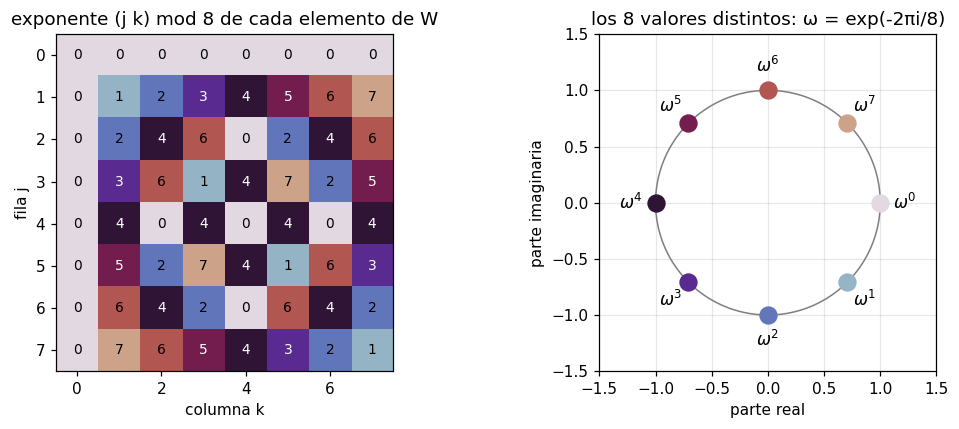

N = 8: W tiene 64 elementos y solo 8 valores distintos


In [4]:
# Figura: los elementos de W son N puntos del círculo unitario, que se repiten
N = 8
W = matriz_dft(N)
residuo = np.outer(np.arange(N), np.arange(N)) % N          # (j k) mod N

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
im = ax[0].imshow(residuo, cmap="twilight", vmin=0, vmax=N)
for (j, k), r in np.ndenumerate(residuo):
    ax[0].text(k, j, str(r), ha="center", va="center", fontsize=9, color="white" if r in (3, 4, 5) else "k")
ax[0].set(title="exponente (j k) mod 8 de cada elemento de W", xlabel="columna k", ylabel="fila j")
ax[0].grid(False)

theta = np.linspace(0, 2*np.pi, 300)
ax[1].plot(np.cos(theta), np.sin(theta), color=GRIS, lw=1)
for m in range(N):
    w = np.exp(-2j*np.pi*m/N)
    ax[1].plot(w.real, w.imag, "o", ms=11, color=plt.cm.twilight(m/N))
    ax[1].text(1.22*w.real, 1.22*w.imag, f"$\\omega^{m}$", ha="center", va="center", fontsize=11)
ax[1].set(aspect="equal", xlim=(-1.5, 1.5), ylim=(-1.5, 1.5), title="los 8 valores distintos: ω = exp(-2πi/8)",
          xlabel="parte real", ylabel="parte imaginaria")
plt.tight_layout(); plt.show()
print(f"N = {N}: W tiene {N*N} elementos y solo {len(np.unique(np.round(W, 12)))} valores distintos")

## 2. El algoritmo de Cooley-Tukey: dividir en pares e impares

Se supone que $N$ es una **potencia de 2**. La suma de la DFT se separa en las muestras de índice par, $k = 2m$, y las de índice impar, $k = 2m + 1$, con $m = 0, 1, \dots, N/2 - 1$:

$$X_j = \sum_{m=0}^{N/2-1} x_{2m}\, \omega_N^{\,2mj} \;+\; \sum_{m=0}^{N/2-1} x_{2m+1}\, \omega_N^{\,(2m+1)j}.$$

Dos propiedades de $\omega_N$ permiten reescribir esta suma:

- $\omega_N^2 = e^{-2\pi i\cdot 2/N} = e^{-2\pi i/(N/2)} = \omega_{N/2}$: el cuadrado de la raíz $N$-ésima es la raíz $(N/2)$-ésima.
- $\omega_N^{(2m+1)j} = \omega_N^{\,j}\,\omega_N^{\,2mj}$: el factor $\omega_N^j$ no depende de $m$ y sale de la suma.

Con ellas,

$$X_j = \underbrace{\sum_{m=0}^{N/2-1} x_{2m}\, \omega_{N/2}^{\,mj}}_{E_j} \;+\; \omega_N^{\,j}\underbrace{\sum_{m=0}^{N/2-1} x_{2m+1}\, \omega_{N/2}^{\,mj}}_{O_j},$$

donde

- $E_j$ es la **DFT de las $N/2$ muestras pares**, $(x_0, x_2, x_4, \dots)$;
- $O_j$ es la **DFT de las $N/2$ muestras impares**, $(x_1, x_3, x_5, \dots)$;
- $\omega_N^{\,j}$ es el **factor de giro** (*twiddle factor*), que corrige que las muestras impares estén corridas una posición.

Cada una de esas DFT tiene solo $N/2$ coeficientes distintos, porque es periódica con período $N/2$: $E_{j+N/2} = E_j$ y $O_{j+N/2} = O_j$. Además, $\omega_N^{\,j+N/2} = \omega_N^{\,j}\,\omega_N^{N/2} = -\omega_N^{\,j}$. Por eso, para $j = 0, 1, \dots, N/2 - 1$,

$$\boxed{\;X_j = E_j + \omega_N^{\,j}\, O_j, \qquad X_{j+N/2} = E_j - \omega_N^{\,j}\, O_j\;}$$

Con un solo producto $\omega_N^j O_j$ se obtienen **dos** coeficientes. Esta operación se llama **mariposa** (*butterfly*), por la forma de su diagrama.

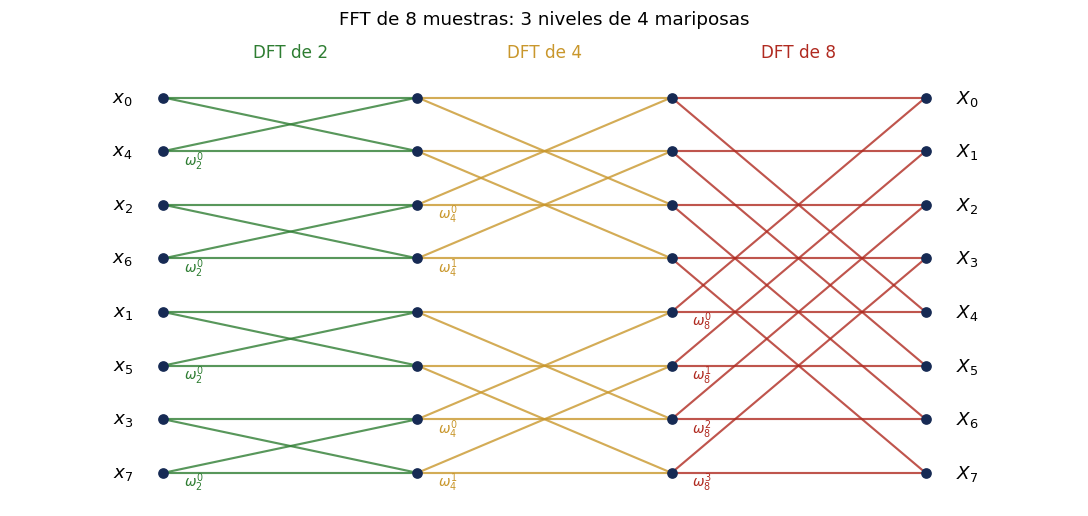

In [14]:
# Figura: diagrama de mariposas de la FFT para N = 8
def invertir_bits(k, bits):
    """Índice k con sus bits en orden inverso (orden en que la recursión deja las muestras)."""
    return int(format(k, f"0{bits}b")[::-1], 2)

N, niveles = 8, 3
orden = [invertir_bits(k, niveles) for k in range(N)]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axis("off")
colores_nivel = [VERDE, DORADO, ROJO]
for nivel in range(niveles):
    paso = 2**nivel                          # distancia entre los dos elementos de cada mariposa
    for inicio in range(0, N, 2*paso):
        for q in range(paso):
            a, b = inicio + q, inicio + q + paso
            for (y0, y1) in [(a, a), (a, b), (b, a), (b, b)]:
                ax.plot([nivel, nivel + 1], [-y0, -y1], color=colores_nivel[nivel], lw=1.4, alpha=0.8)
            ax.text(nivel + 0.08, -b - 0.25, f"$\\omega_{{{2*paso}}}^{{{q}}}$", fontsize=9, color=colores_nivel[nivel])
for nivel in range(niveles + 1):
    for y in range(N):
        ax.plot(nivel, -y, "o", color=AZUL, ms=6, zorder=5)
for y in range(N):
    ax.text(-0.12, -y, f"$x_{orden[y]}$", ha="right", va="center", fontsize=12)
    ax.text(niveles + 0.12, -y, f"$X_{y}$", ha="left", va="center", fontsize=12)
for nivel, texto in enumerate(["DFT de 2", "DFT de 4", "DFT de 8"]):
    ax.text(nivel + 0.5, 0.75, texto, ha="center", fontsize=11, color=colores_nivel[nivel])
ax.set(xlim=(-0.6, niveles + 0.6), ylim=(-N + 0.4, 1.2))
ax.set_title("FFT de 8 muestras: 3 niveles de 4 mariposas")
plt.tight_layout(); plt.show()

**Lectura del diagrama.** A la izquierda están las muestras en el orden en que las deja la separación repetida en pares e impares ($x_0, x_4, x_2, x_6, \dots$, el orden de **bits invertidos**). Cada nivel combina parejas de DFT pequeñas en una DFT del doble de tamaño con mariposas: dos líneas que se cruzan, con el factor de giro indicado. Con $N = 8$ hay $\log_2 8 = 3$ niveles de $N/2 = 4$ mariposas.

### 2.1 Ejemplo con $N = 4$

Con $x = (1, 2, 3, 4)$, el mismo ejemplo de la Semana 10:

- Muestras pares $(1, 3)$: $E_0 = 1 + 3 = 4$, $\;E_1 = 1 - 3 = -2$.
- Muestras impares $(2, 4)$: $O_0 = 2 + 4 = 6$, $\;O_1 = 2 - 4 = -2$.
- Factores de giro: $\omega_4^0 = 1$, $\;\omega_4^1 = e^{-i\pi/2} = -i$.

Las mariposas dan

$$X_0 = E_0 + O_0 = 10, \quad X_2 = E_0 - O_0 = -2, \quad X_1 = E_1 + (-i)\,O_1 = -2 + 2i, \quad X_3 = E_1 - (-i)\,O_1 = -2 - 2i,$$

que es el resultado de $W\mathbf{x}$ de la Semana 10.

## 3. FFT recursiva en Python

La fórmula de la mariposa se aplica de nuevo a $E$ y a $O$, que también tienen un número par de muestras, y así hasta llegar a DFT de **una** muestra, que son la muestra misma ($X_0 = x_0$). Esto se programa directamente con una **función recursiva**: una función que se llama a sí misma con un problema más pequeño, y que tiene un **caso base** que termina la recursión.

```
función FFT(x):
    N ← número de muestras
    si N = 1: devolver x                         (caso base)
    E ← FFT(muestras pares de x)                 (problema de tamaño N/2)
    O ← FFT(muestras impares de x)               (problema de tamaño N/2)
    para j = 0, ..., N/2 - 1:
        X[j]       ← E[j] + ω_N^j O[j]           (mariposa)
        X[j + N/2] ← E[j] - ω_N^j O[j]
    devolver X
```

In [15]:
def fft_recursiva(x):
    """FFT de Cooley-Tukey (radix 2), recursiva. len(x) debe ser una potencia de 2."""
    x = np.asarray(x, dtype=complex)
    N = len(x)
    if N == 1:                                    # caso base: la DFT de una muestra es la muestra
        return x.copy()
    if N % 2 != 0:
        raise ValueError("el número de muestras debe ser una potencia de 2")
    E = fft_recursiva(x[0::2])                    # DFT de las muestras pares   x0, x2, x4, ...
    O = fft_recursiva(x[1::2])                    # DFT de las muestras impares x1, x3, x5, ...
    giro = np.exp(-2j*np.pi*np.arange(N//2)/N)    # factores de giro omega_N^j, j = 0, ..., N/2 - 1
    return np.concatenate([E + giro*O,            # X_j        = E_j + omega^j O_j
                           E - giro*O])           # X_{j+N/2}  = E_j - omega^j O_j

# Ejemplo de la sección 2.1
print("FFT de (1, 2, 3, 4) =", fft_recursiva([1, 2, 3, 4]))

# Comparación con la DFT matricial de la Semana 10 y con NumPy
x = np.random.default_rng(2026).normal(size=1024)
print("máx |FFT - W x|      =", np.max(np.abs(fft_recursiva(x) - matriz_dft(1024) @ x)))
print("máx |FFT - np.fft|   =", np.max(np.abs(fft_recursiva(x) - np.fft.fft(x))))

FFT de (1, 2, 3, 4) = [10.+0.j -2.+2.j -2.+0.j -2.-2.j]
máx |FFT - W x|      = 1.964971859972573e-11
máx |FFT - np.fft|   = 4.5496934130773415e-14


<div style="border-left: 5px solid #162A54; background-color: #EEF1F7; padding: 10px 14px; margin: 8px 0;">

**La FFT no es una aproximación.** Da exactamente los mismos coeficientes que $W\mathbf{x}$; la diferencia, del orden de $10^{-12}$, es redondeo. Lo que cambia es el número de operaciones. `np.fft.fft` usa una versión muy optimizada del mismo algoritmo (y de variantes para $N$ que no son potencias de 2).

</div>

### 3.1 La transformada inversa con la misma función

En la Semana 10 se vio que la inversa es $\mathbf{x} = W^H\mathbf{X}/N$. Conjugar dos veces deja un número igual, de modo que

$$\mathbf{x} = \frac{1}{N}\,\overline{W\,\overline{\mathbf{X}}},$$

es decir: se conjugan los coeficientes, se aplica la **misma** FFT directa, se conjuga el resultado y se divide por $N$. No hace falta programar otra función.

In [16]:
def ifft_recursiva(X):
    """Transformada inversa con la FFT directa: x = conj(FFT(conj(X))) / N."""
    X = np.asarray(X, dtype=complex)
    return np.conj(fft_recursiva(np.conj(X))) / len(X)

x = np.random.default_rng(7).normal(size=256)
print("máx |ifft(fft(x)) - x| =", np.max(np.abs(ifft_recursiva(fft_recursiva(x)) - x)))

máx |ifft(fft(x)) - x| = 1.0470214982037715e-15


<div style="border-left: 5px solid #B02A20; background-color: #FBEDEC; padding: 10px 14px; margin: 8px 0;">

**$N$ debe ser una potencia de 2** en esta versión. Si la señal tiene, por ejemplo, 1000 muestras, la separación en pares e impares falla en algún nivel. Lo usual es **rellenar con ceros** hasta la siguiente potencia de 2 (1024), sabiendo que eso cambia la resolución en frecuencia, $\Delta f = 1/(N\Delta t)$, con el nuevo $N$. No recorte la señal para que encaje: perdería información.

</div>

## 4. Costo: $O(N\log_2 N)$ frente a $O(N^2)$

Cada nivel de la recursión hace $N/2$ mariposas, con una multiplicación compleja cada una ($\omega_N^j\,O_j$), y hay $\log_2 N$ niveles, porque $N$ se divide por 2 hasta llegar a 1. El número de multiplicaciones es

$$M_{\text{FFT}} = \frac{N}{2}\log_2 N \qquad\text{frente a}\qquad M_{\text{DFT}} = N^2 .$$

| $N$ | DFT matricial, $N^2$ | FFT, $\frac{N}{2}\log_2 N$ | razón |
|---|---|---|---|
| 8 | 64 | 12 | 5.3 |
| 1 024 | 1 048 576 | 5 120 | 205 |
| 65 536 | $4.3\times10^{9}$ | 524 288 | 8 192 |
| 1 048 576 | $1.1\times10^{12}$ | $1.0\times10^{7}$ | 104 858 |

La ventaja crece con $N$: la razón es $2N/\log_2 N$. La celda siguiente lo mide.

In [17]:
def mejor_tiempo(funcion, repeticiones=3):
    """Menor tiempo de ejecución [s] entre varias repeticiones (Semana 9)."""
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        funcion()
        tiempos.append(time.perf_counter() - t0)
    return min(tiempos)

In [18]:
# Tiempos: DFT matricial (hasta N = 4096), FFT recursiva en Python y np.fft
tam_dft = [2**p for p in range(6, 13)]
tam_fft = [2**p for p in range(6, 17)]
t_dft = [mejor_tiempo(lambda: matriz_dft(N) @ np.ones(N)) for N in tam_dft]
t_fft = [mejor_tiempo(lambda: fft_recursiva(np.ones(N))) for N in tam_fft]
t_np  = [mejor_tiempo(lambda: np.fft.fft(np.ones(N)), 5) for N in tam_fft]

print("     N    DFT matricial    FFT recursiva      np.fft")
for i, N in enumerate(tam_fft):
    td = f"{t_dft[i]*1e3:10.2f} ms" if N in tam_dft else " "*13
    print(f"{N:6d}   {td}    {t_fft[i]*1e3:10.2f} ms   {t_np[i]*1e3:8.3f} ms")

     N    DFT matricial    FFT recursiva      np.fft
    64         0.93 ms          0.35 ms      0.007 ms
   128         1.15 ms          0.71 ms      0.007 ms
   256         4.59 ms          1.43 ms      0.008 ms
   512         7.66 ms          2.86 ms      0.010 ms
  1024        26.73 ms          5.71 ms      0.014 ms
  2048       103.06 ms         11.45 ms      0.022 ms
  4096       391.34 ms         22.84 ms      0.048 ms
  8192                         44.27 ms      0.139 ms
 16384                         88.37 ms      0.441 ms
 32768                        180.44 ms      0.986 ms
 65536                        360.39 ms      1.819 ms


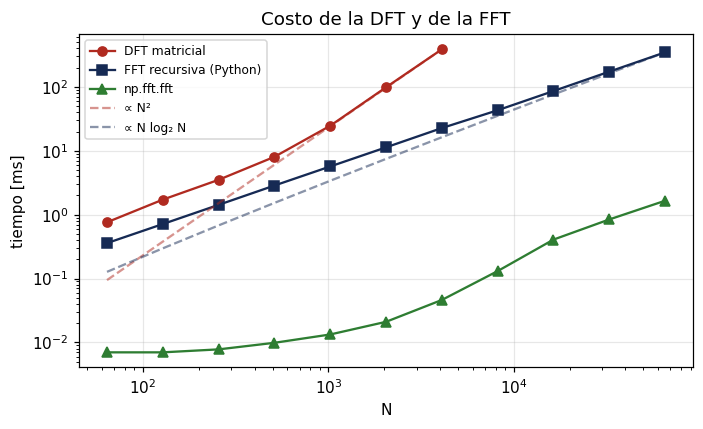

In [10]:
# Figura: tiempo frente a N en escala log-log, con las referencias N^2 y N log2 N
Nf = np.array(tam_fft, float)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(tam_dft, np.array(t_dft)*1e3, "o-", color=ROJO, label="DFT matricial")
ax.loglog(tam_fft, np.array(t_fft)*1e3, "s-", color=AZUL, label="FFT recursiva (Python)")
ax.loglog(tam_fft, np.array(t_np)*1e3, "^-", color=VERDE, label="np.fft.fft")
ax.loglog(tam_dft, t_dft[-1]*1e3*(np.array(tam_dft)/tam_dft[-1])**2, "--", color=ROJO, alpha=0.5, label="∝ N²")
ax.loglog(Nf, t_fft[-1]*1e3*(Nf*np.log2(Nf))/(Nf[-1]*np.log2(Nf[-1])), "--", color=AZUL, alpha=0.5, label="∝ N log₂ N")
ax.set(xlabel="N", ylabel="tiempo [ms]", title="Costo de la DFT y de la FFT")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Para $N$ pequeño la DFT matricial puede ser más rápida que la FFT recursiva de Python, porque cada llamada recursiva tiene un costo fijo del intérprete. Desde unos cientos de muestras la FFT gana, y la distancia crece sin límite: la recta de la DFT tiene pendiente 2 y la de la FFT, pendiente casi 1. `np.fft` sigue la misma pendiente que la FFT recursiva, pero desplazada hacia abajo: es el mismo algoritmo en código compilado.

<div style="border: 2px solid #C9972C; background-color: #FBF6EA; padding: 10px 14px; margin: 8px 0;">

**Ejercicio de calentamiento 1 (no calificado): contar las multiplicaciones**

La sección 4 afirma que la FFT hace $\frac{N}{2}\log_2 N$ multiplicaciones complejas. Compruébelo con un contador.

1. En la celda siguiente, la función `fft_contada` es una copia de `fft_recursiva`. Agregue la cuenta de las multiplicaciones $\omega_N^j\,O_j$ en la variable global `multiplicaciones`.
2. Para $N = 8, 64, 1024$ y $4096$, obtenga el número de multiplicaciones, compárelo con $\frac{N}{2}\log_2 N$ y obtenga la razón $N^2 / M_{\text{FFT}}$.

**Debe obtener:** 12, 192, 5 120 y 24 576 multiplicaciones, iguales a la fórmula, y razones de 5.3, 21.3, 204.8 y 682.7.

</div>

In [19]:
# Ejercicio de calentamiento 1
multiplicaciones = 0

def fft_contada(x):
    '''Copia de fft_recursiva que cuenta las multiplicaciones complejas.'''
    x = np.asarray(x, dtype=complex)
    N = len(x)
    if N == 1:
        return x.copy()
    E = fft_contada(x[0::2])
    O = fft_contada(x[1::2])
    giro = np.exp(-2j*np.pi*np.arange(N//2)/N)
    # TODO: acumule en la variable global multiplicaciones las multiplicaciones de este nivel
    producto = giro*O
    return np.concatenate([E + producto, E - producto])

# TODO: para N = 8, 64, 1024, 4096, obtenga las multiplicaciones contadas,
#       la fórmula (N/2) log2 N y la razón N^2 / M

## 5. FFT recursiva en Fortran

Fortran admite subrutinas recursivas desde Fortran 90 con la palabra `recursive`. El módulo siguiente programa la misma FFT y se compila como librería con F2PY, igual que la librería `fou` del Taller 10.

Dos detalles de Fortran:

- Las muestras pares de Python ($k = 0, 2, 4, \dots$) son los índices impares de Fortran ($1, 3, 5, \dots$), porque Fortran numera desde 1: la sección `x(1:n:2)` contiene $x_0, x_2, \dots$ y `x(2:n:2)` contiene $x_1, x_3, \dots$
- Los arreglos de trabajo `e` y `o` son `allocatable`: en cada nivel de la recursión se crean en la memoria dinámica (Capítulo 3) y no en la pila.

In [20]:
%%writefile modulo_rapida.f90
! ============================================================
! Módulo:    rapida
! Propósito: transformada rápida de Fourier (Cooley-Tukey,
!            radix 2), recursiva, para usar desde Python con F2PY.
! ============================================================
module rapida
  implicit none
contains

  ! fft: transformada directa de n muestras, n potencia de 2
  ! Entrada: x(n), complejo
  ! Salida:  xf(n), con xf(j+1) = X_j
  recursive subroutine fft(n, x, xf)
    integer,    intent(in)  :: n
    complex(8), intent(in)  :: x(n)
    complex(8), intent(out) :: xf(n)
    real(8), parameter :: pi = 3.141592653589793d0
    complex(8), allocatable :: e(:), o(:)
    complex(8) :: giro
    integer :: j

    if (n == 1) then                       ! caso base: la DFT de una muestra es la muestra
       xf = x
       return
    end if

    allocate(e(n/2), o(n/2))
    call fft(n/2, x(1:n:2), e)             ! muestras pares de Python:   x0, x2, x4, ...
    call fft(n/2, x(2:n:2), o)             ! muestras impares de Python: x1, x3, x5, ...

    do j = 1, n/2                          ! mariposas; j-1 es el índice de Python
       giro = exp(cmplx(0.0d0, -2.0d0*pi*dble(j-1)/dble(n), kind=8))
       xf(j)       = e(j) + giro*o(j)
       xf(j + n/2) = e(j) - giro*o(j)
    end do
    deallocate(e, o)
  end subroutine fft

end module rapida

Overwriting modulo_rapida.f90


In [13]:
# Compila la librería "rapf" y la compara con la versión de Python
!python -m numpy.f2py -c modulo_rapida.f90 -m rapf 2>&1 | tail -n 1
import rapf
print(rapf.rapida.fft.__doc__)

x = np.random.default_rng(11).normal(size=4096)
print("máx |FFT Fortran - FFT Python| =", np.max(np.abs(rapf.rapida.fft(x) - fft_recursiva(x))))

for N in [1024, 16384, 65536]:
    x = np.random.default_rng(N).normal(size=N)
    tf = mejor_tiempo(lambda: rapf.rapida.fft(x))
    tp = mejor_tiempo(lambda: fft_recursiva(x))
    print(f"N = {N:6d}:  Fortran {tf*1e3:8.2f} ms   Python {tp*1e3:8.2f} ms   razón {tp/tf:5.1f}")

Removing build directory /var/folders/f1/vx4t6md906z5fb0jhmbsxst40000gn/T/tmpdzv19620


ImportError: dlopen(/Users/cpinilla/Dropbox/01.UNIVALLE/Periodo_prueba_2026_2027/01.docencia/02.Fisica_Computacional/11.FFT/rapf.cpython-39-darwin.so, 0x0002): tried: '/opt/homebrew/lib/rapf.cpython-39-darwin.so' (no such file), '/rapf.cpython-39-darwin.so' (no such file), '/Users/cpinilla/Dropbox/01.UNIVALLE/Periodo_prueba_2026_2027/01.docencia/02.Fisica_Computacional/11.FFT/rapf.cpython-39-darwin.so' (mach-o file, but is an incompatible architecture (have 'arm64', need 'x86_64')), '/System/Volumes/Preboot/Cryptexes/OS/Users/cpinilla/Dropbox/01.UNIVALLE/Periodo_prueba_2026_2027/01.docencia/02.Fisica_Computacional/11.FFT/rapf.cpython-39-darwin.so' (no such file), '/Users/cpinilla/Dropbox/01.UNIVALLE/Periodo_prueba_2026_2027/01.docencia/02.Fisica_Computacional/11.FFT/rapf.cpython-39-darwin.so' (mach-o file, but is an incompatible architecture (have 'arm64', need 'x86_64'))

<div style="border-left: 5px solid #2E7D32; background-color: #EAF5EA; padding: 10px 14px; margin: 8px 0;">

**Por qué Fortran gana aquí.** La FFT recursiva hace $N - 1$ llamadas a la función. En Python cada llamada tiene un costo fijo del intérprete; en Fortran, una llamada es apenas un salto en el código compilado. El algoritmo es el mismo: la mejora es un factor constante, no un cambio de orden.

</div>

## 6. Aplicación: una señal oculta en el ruido

Un sensor registra durante 1 s, a $f_s = 1024$ muestras por segundo, la señal

$$x(t) = \sin(2\pi\,50\,t) + 0.5\,\sin(2\pi\,120\,t) + \varepsilon(t),$$

donde $\varepsilon(t)$ es ruido aleatorio de desviación estándar 2: el ruido es el **doble** de la amplitud de la componente mayor. En el dominio del tiempo no se ve ninguna oscilación. En el dominio de la frecuencia, en cambio, la energía de cada oscilación se concentra en un solo coeficiente, mientras que la del ruido se reparte entre todos. Con $N = 1024$ y $\Delta t = 1/1024$ s, la resolución es $\Delta f = 1$ Hz y las dos frecuencias caen exactamente en los coeficientes $j = 50$ y $j = 120$.

In [ ]:
fs, N = 1024, 1024                             # muestras por segundo y número de muestras
t = np.arange(N)/fs                            # 1 s de registro
limpia = np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*120*t)
x = limpia + 2.0*np.random.default_rng(42).normal(size=N)

X = rapf.rapida.fft(x)                         # FFT en Fortran
f = np.arange(N)*fs/N                          # frecuencia de cada coeficiente [Hz]
A = 2*np.abs(X)/N                              # amplitud (Semana 10)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(t[:200], x[:200], color=GRIS, lw=0.8, label="registro con ruido")
ax[0].plot(t[:200], limpia[:200], color=AZUL, lw=1.5, label="señal sin ruido")
ax[0].set(xlabel="t [s]", ylabel="x(t)", title="Dominio del tiempo (primeros 0.2 s)"); ax[0].legend(fontsize=8)
ax[1].plot(f[:N//2 + 1], A[:N//2 + 1], color=AZUL, lw=0.8)
ax[1].set(xlabel="f [Hz]", ylabel="amplitud", title="Dominio de la frecuencia")
for j in np.argsort(A[:N//2])[-2:]:
    ax[1].annotate(f"{f[j]:.0f} Hz: {A[j]:.2f}", (f[j], A[j]), textcoords="offset points", xytext=(8, -4), color=ROJO)
plt.tight_layout(); plt.show()

Los dos picos sobresalen claramente sobre el fondo del ruido, con amplitudes cercanas a 1 y 0.5. Para **recuperar** la señal se conservan solo los coeficientes cuya amplitud supera un umbral, por encima del fondo del ruido, y se aplica la transformada inversa. Como el umbral se aplica igual a $X_j$ y a $X_{N-j}$, la simetría de la Semana 10 se conserva y la señal recuperada es real.

In [ ]:
umbral = 0.3
X_filtrado = np.where(A > umbral, X, 0)                      # conserva solo los picos
x_rec = np.conj(rapf.rapida.fft(np.conj(X_filtrado)))/N      # inversa con la FFT directa (sección 3.1)

print("coeficientes conservados (j):", np.where(A > umbral)[0])
print(f"máx |Im x_rec| = {np.max(np.abs(x_rec.imag)):.1e}")
print(f"error cuadrático medio: registro {np.sqrt(np.mean((x - limpia)**2)):.3f},"
      f"  recuperada {np.sqrt(np.mean((x_rec.real - limpia)**2)):.3f}")

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(t[:200], limpia[:200], color=AZUL, lw=2.5, alpha=0.5, label="señal sin ruido")
ax.plot(t[:200], x_rec.real[:200], "--", color=ROJO, lw=1.2, label="recuperada con la FFT")
ax.set(xlabel="t [s]", ylabel="x(t)", title="Señal recuperada del ruido"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Resumen

| | DFT matricial (Semana 10) | FFT (Semana 11) |
|---|---|---|
| Fórmula | $\mathbf{X} = W\mathbf{x}$ | $X_j = E_j + \omega_N^j O_j$, $\;X_{j+N/2} = E_j - \omega_N^j O_j$ |
| Multiplicaciones | $N^2$ | $\frac{N}{2}\log_2 N$ |
| Memoria adicional | la matriz, $N^2$ números | $O(N)$ |
| Restricción | ninguna | $N$ potencia de 2 (en esta versión) |
| Resultado | los coeficientes exactos | **los mismos** coeficientes |

**Continúa en el notebook 11b**: introducción a la solución numérica de ecuaciones diferenciales y Taller 11.